# Reading a coding ban inside Qwen3-8B: demo of the pipeline's CPU stages

**What the research asks.** Ask Qwen3-8B to "implement a path search" and it nearly always writes the textbook algorithm. What happens when the prompt **bans** that default? Two tasks from the iteration-1 suite are used:
- **T1** is a grid path task with **BFS banned**.
- **T2** is a weighted shortest path task with **Dijkstra banned**.

Each is run under five ban wordings (templates W1-W5), 20 runs each, giving a fresh pool of 200 generations (Qwen3-8B-FP8, T = 1.0, thinking off). The artifact asks:
1. **Behaviour.** How often is the banned algorithm still written, and what replaces it?
2. **Readout.** Can the model's choice be read from its residual stream at **k_pre**, the token just before it first names or imports an algorithm? The candidates are Qwen-Scope **SAE latents** (base-model SAE, 65,536 latents, k = 50) against simple baselines: a **difference-of-means (DiM)** direction, logistic probes, and top single neurons. All were fitted on an earlier experiment's states (exp3) and applied unchanged to the fresh runs.

**What `method.py` is, and what runs here.** `method.py` is an orchestrator: `uv run method.py --stage <name>` runs one stage per process. Most stages need Qwen3-8B on a GPU: vLLM for generation, and HF forward passes for the states, attention and SAE codes, about 1 GPU-hour on a 16 GB card. They can't run in Colab. Their outputs are in the demo data, where every run carries its program label and the per-run scores of the seven exp3-fitted readouts at layer 27. This notebook replays the CPU stages with the original code:

| `method.py --stage` | original code | in this notebook |
|---|---|---|
| `A`, `B`, `vllm1`, `vllm2`, `label`, `hf` | prompt build, exp3 discovery, generation, labelling, states / attention / SAE | listed by the dispatcher; outputs come with the data |
| `final` | `src/final.py::fresh_pool_summary` | replayed: banned share per template, Wilson CIs |
| `analyse` | `src/analysis.py::readout_i_replication` with the metrics of `src/readout_i.py` | replayed from the stored scores: pooled and within-template AUC, bootstrap CIs |
| `verify` | `src/verify_headlines.py` | replayed: independent re-derivation (pandas / sklearn) and shuffled-label placebos |

**Data.** `mini_demo_data.json` holds 100 of the 200 fresh-pool runs, 10 per (task, template), with each template's label mix kept. It also carries the full-pool reference numbers, so every result is shown next to the full run's value.

**Full-run headlines** (from the artifact):
- The T1 ban fails almost only for W4 ("Breadth-first search (BFS) is not allowed here."), with 15/20 BFS against 0/20 for every other wording. T2's banned share is 0.13.
- The exp3-fitted DiM direction transfers best: within-template AUC 1.00 (T1) and 0.76 (T2) at L27. The single top SAE latent does not (0.52 / 0.51). A shuffled-label placebo gives ≈ 0.50.
- The SAE's base->instruct transfer test fails at every layer, so every latent result is flagged as computed on out-of-distribution activations.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the original stages log through it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, scikit-learn, matplotlib — pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import os

# The cgroup quota is ~5 CPUs while os.cpu_count() reports 48 host cores: cap every BLAS / OpenMP pool
# BEFORE numpy/torch load, or the oversubscribed thread pools are throttled ~100x.
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_v, "4")
# notebook: method.py also points CC at tools/zigcc, a C-compiler shim for vLLM's Triton kernels; no vLLM runs here.

import sys
from pathlib import Path

from loguru import logger
# notebook: method.py adds src/ to sys.path and imports setup_logging from src/core.py; the src/ code that the
# replayed stages need is copied into the cells below.

# imports of the replayed stage modules (src/final.py, src/analysis.py, src/readout_i.py, src/verify_headlines.py)
import json
import math
from collections import Counter
from typing import Any

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

# notebook addition: figures in the Results section
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-2/experiment-12/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["description"])
print({d["dataset"]: len(d["examples"]) for d in data["datasets"]})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated demo subset of the fresh protocol-v2 ban pool (Qwen3-8B-FP8 generations, T=1.0, thinking off): 100 of 200 runs, 10 per (task, template), each template's label mix kept. Every run carries the exp3-fitted readout scores at layer 27, position k_pre (score > 0 means 'predicts the banned algorithm').
{'fresh_ban_pool_protocol_v2': 100}


## Configuration

All tunable parameters live here, set to the **original values**: every demo run, the 2000 bootstrap draws of `src/analysis.py`, and the 200 placebo draws of `src/verify_headlines.py`. The replayed stages are light, so the whole notebook still runs in well under a minute.
- `RUNS_PER_TEMPLATE` is how many runs of each (task, template) cell are used. The demo data holds 10 per cell; `None` uses them all. 4 gives a quick smoke test.
- `N_BOOT` is the number of bootstrap draws behind every AUC confidence interval. Fewer than 21 gives no interval.
- `N_PLACEBO` is the number of shuffled-label placebo draws in `verify`.
- `READOUT_LAYER` is fixed by the data: the stored scores come from layer 27, the deepest of the three layers (15, 20, 27) the pipeline's layer choice picked.

In [5]:
# ---- tunable parameters: the original values (the whole notebook still runs in well under a minute) ----
RUNS_PER_TEMPLATE = None  # runs per (task, template) cell; None = all 10 in the demo data (full pool: 20)   quick test: 4
N_BOOT = 2000             # bootstrap resamples over runs for the AUC CIs, as src/analysis.py N_BOOT        quick test: 21
N_PLACEBO = 200           # shuffled-label placebo draws per check, as in src/verify_headlines.py           quick test: 1
READOUT_LAYER = 27        # layer of the stored exp3-fitted readout scores (fixed by the data; the pipeline also has 15, 20)

## 1. Protocol constants and helpers (`src/core.py`)

Every stage of the pipeline imports `src/core.py`, so the protocol constants live in one place:
- the models;
- the two tasks;
- the banned algorithm X and its main substitute X′;
- the five frozen **protocol-v2 ban templates** (each with matched *mention* and *neutral* twins, used by the attention and prime-veto readouts);
- the fresh-pool seed.

The cell also has the JSON writer, the Wilson interval and the loguru setup. The code is copied verbatim, keeping only what the replayed stages use. The only change is that output goes to local `results/` and `logs/` folders.

In [6]:
RESULTS = Path("results")  # notebook: local folders instead of ROOT / "results", ROOT / "logs"
LOGS = Path("logs")
for _d in (RESULTS, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- models (see deviations.json D01)
MODEL_HF = "Qwen/Qwen3-8B"            # bf16 weights: every state / attention / CE readout
MODEL_GEN = "Qwen/Qwen3-8B-FP8"       # official block-FP8 checkpoint: every vLLM generation (16 GB GPU)
MODEL_BASE = "Qwen/Qwen3-8B-Base"     # SAE training model, for the transfer test
SAE_REPO = "Qwen/SAE-Res-Qwen3-8B-Base-W64K-L0_50"
SAE_K = 50

TASKS = ("t1", "t2")
BANNED = {"t1": "bfs", "t2": "dijkstra"}           # X: the modal approach that the ban names
SUBSTITUTE = {"t1": "dfs", "t2": "bf_spfa"}        # X': the main natural substitute under the ban
X_NAME = {"t1": "breadth-first search (BFS)", "t2": "Dijkstra" + chr(39) + "s algorithm"}
XSUB_NAME = {"t1": "depth-first search (DFS)", "t2": "Bellman-Ford or SPFA"}

# Frozen protocol-v2 templates: (ban, mention, neutral)
TEMPLATES: dict[str, tuple[str, str, str]] = {
    "W1": ("Do not use {X} for this task.", "You could use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution may rely on {X}.",
           "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Consider {X} first.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{X} is allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that may use {X}.",
           "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)

# ---------------------------------------------------------------- seeds (plan CONVENTIONS)
SEED_FRESH = 20261020        # fresh pool: 20261020 + i


def setup_logging(name: str) -> None:
    """loguru: stdout INFO + rotating DEBUG file sink per stage."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _clean_nan(o: Any) -> Any:
    if isinstance(o, float) and not math.isfinite(o):
        return None
    if isinstance(o, dict):
        return {k: _clean_nan(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean_nan(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_clean_nan(json.loads(json.dumps(obj, default=_json_default))), indent=indent,
                              ensure_ascii=False))
    tmp.replace(p)


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float | None, float | None]:
    if n <= 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s

## 2. From the loaded JSON to the pipeline's labelled rows

The stages read `results/labelled_c1.jsonl`, one labelled program per fresh-pool generation. The demo data is the artifact's `exp_gen_sol_out` export of those rows:

- `input` is the full prompt: the ban sentence, then the task.
- `output` is the canonical label from the labeller (hidden tests, an execution tracer and AST rules, plus an LLM judge where runtime and AST disagree): `bfs`, `dfs`, `dijkstra`, `bf_spfa` or `other`.
- `metadata_*` holds the template, seed, hidden-test pass, commit index, negated-first-mention flag and so on.
- `metadata_readout_scores_k_pre` holds the seven exp3-fitted readout scores. It is empty when no k_pre state was found.

This cell rebuilds the row dicts the original functions expect. It's the only new processing code in the notebook. `RUNS_PER_TEMPLATE` keeps the first N runs of every (task, template) cell. The data file interleaves the labels inside each cell, so any prefix keeps roughly that cell's label mix.

In [7]:
# The pipeline's stages read results/labelled_c1.jsonl (one labelled row per fresh-pool generation) plus the
# per-run readout scores. The exp_gen_sol_out examples carry the same fields under metadata_* names, so the
# rows the stage functions expect are rebuilt here; RUNS_PER_TEMPLATE keeps the first runs of every cell.
FRESH = next(d for d in data["datasets"] if d["dataset"] == "fresh_ban_pool_protocol_v2")["examples"]
_per_cell: Counter = Counter()
C1_ROWS: list[dict[str, Any]] = []
for e in FRESH:
    cell = (e["metadata_task"], e["metadata_template"])
    if RUNS_PER_TEMPLATE is not None and _per_cell[cell] >= RUNS_PER_TEMPLATE:
        continue
    _per_cell[cell] += 1
    C1_ROWS.append({"task": e["metadata_task"], "template": e["metadata_template"],
                    "sample_id": e["metadata_seed"] - SEED_FRESH,  # run index i: fresh-pool seed = 20261020 + i
                    "seed": e["metadata_seed"], "label": e["output"], "passed": e["metadata_passed"],
                    "labeller_source": e["metadata_labeller_source"], "commit_idx": e["metadata_commit_idx"],
                    "evidence_term": e["metadata_evidence_term"],
                    "negated_first_mention": e["metadata_negated_first_mention"],
                    "n_gen_tokens": e["metadata_n_gen_tokens"],
                    "scores": e["metadata_readout_scores_k_pre"],  # {} when no k_pre state was recorded
                    "stored_predictions": {k: v for k, v in e.items() if k.startswith("predict_")},
                    "prompt": e["input"]})

print(f"{len(C1_ROWS)} runs; labels per task:", dict(Counter((r["task"], r["label"]) for r in C1_ROWS)))
for t in TASKS:  # the ban sentence that opens each prompt
    for w in TEMPLATE_IDS:
        r = next(r for r in C1_ROWS if r["task"] == t and r["template"] == w)
        print(f"  {t} {w}: {r['prompt'].splitlines()[0]}")
pd.DataFrame(C1_ROWS)[["task", "template", "seed", "label", "passed", "labeller_source", "evidence_term",
                       "negated_first_mention", "n_gen_tokens"]].head(10)

100 runs; labels per task: {('t1', 'dfs'): 43, ('t1', 'bfs'): 7, ('t2', 'bf_spfa'): 42, ('t2', 'dijkstra'): 7, ('t2', 'other'): 1}
  t1 W1: Do not use breadth-first search (BFS) for this task.
  t1 W2: Your solution must not rely on breadth-first search (BFS).
  t1 W3: Avoid breadth-first search (BFS) entirely.
  t1 W4: Breadth-first search (BFS) is not allowed here.
  t1 W5: Write a correct solution that does not use breadth-first search (BFS).
  t2 W1: Do not use Dijkstra's algorithm for this task.
  t2 W2: Your solution must not rely on Dijkstra's algorithm.
  t2 W3: Avoid Dijkstra's algorithm entirely.
  t2 W4: Dijkstra's algorithm is not allowed here.
  t2 W5: Write a correct solution that does not use Dijkstra's algorithm.


,task,template,seed,label,passed,labeller_source,evidence_term,negated_first_mention,n_gen_tokens
0,t1,W1,20261020,dfs,False,agree,stack,False,258
1,t1,W1,20261021,dfs,False,agree,dfs,False,221
2,t1,W1,20261023,dfs,True,agree,dfs,False,352
3,t1,W1,20261024,dfs,True,agree,dfs,False,296
4,t1,W1,20261026,dfs,False,agree,stack,False,229
5,t1,W1,20261027,dfs,False,agree,dfs,False,223
6,t1,W1,20261029,dfs,True,agree,stack,False,268
7,t1,W1,20261036,dfs,False,agree,dfs,False,335
8,t1,W1,20261037,dfs,False,agree,stack,False,245
9,t1,W1,20261038,dfs,False,agree,dfs,False,246


## 3. The orchestrator (`method.py`)

`method.py` is the artifact's entry point. `uv run method.py --stage <name>` runs one stage per process, because vLLM and the HF model never share the 16 GB GPU. Its `main()` is a plain dispatcher, kept here with two changes. The CLI parsing is gone, so the stage is passed as an argument. The branches for stages that can't run on a CPU runtime now log what they would need instead of importing their module. The loop below calls those stages in the README's order so the full pipeline is visible. The three replayable stages (`final`, `analyse`, `verify`) run through this same `main()` in the next sections.

In [8]:
def _not_here(stage: str, needs: str) -> None:
    logger.warning(f"stage {stage}: not replayed here (needs {needs}); its outputs are in the loaded data")


@logger.catch(reraise=True)
def main(stage: str) -> Any:
    # notebook: argparse removed; the stage is the argument (--smoke / --n / --part only steer GPU stages)
    setup_logging(f"stage_{stage}")
    logger.info(f"stage {stage} (smoke=False)")
    if stage == "A":
        _not_here(stage, "the iteration-1 input folders: inputs check, labeller re-check, prompt build")
    elif stage == "B":
        _not_here(stage, "the ~800 MB exp3 activation states and the Qwen-Scope SAE weights")
    elif stage == "vllm1":
        _not_here(stage, "vLLM + Qwen3-8B-FP8 on a GPU: C1 fresh pool, E5 same-seed CRN")
    elif stage == "vllm2":
        _not_here(stage, "vLLM + Qwen3-8B-FP8 on a GPU: thought-anchor traces and resampling")
    elif stage == "label":
        _not_here(stage, "the canonical labeller: hidden tests, tracer, AST rules, OpenRouter judge")
    elif stage == "hf":
        _not_here(stage, "bf16 Qwen3-8B forward passes on a GPU: E1 transfer test, E2 states/attention, E4 J-lens")
    elif stage == "analyse":
        # notebook: the readout (i) replication part of run_stage_analyse(), from the stored per-run scores
        return readout_i_replication()
    elif stage == "anchors":
        _not_here(stage, "the thought-anchor continuations, a different dataset of the output")
    elif stage == "figures":
        _not_here(stage, "every stage's results/*.json; the Results section draws this demo's figures")
    elif stage == "verify":
        # notebook: method.py runs src/verify_headlines.py through runpy; its main() is verify() here
        return verify()
    elif stage == "final":
        # notebook: the fresh-pool part of run_stage_final()
        return fresh_pool_summary()
    else:
        raise SystemExit(f"unknown stage {stage}")


# README run order: these stages need a GPU or inputs that are not in the demo data, so they only report.
for _stage in ("A", "B", "vllm1", "vllm2", "label", "hf"):
    main(_stage)

06:31:33|INFO   |stage A (smoke=False)


06:31:33|WARNING|stage A: not replayed here (needs the iteration-1 input folders: inputs check, labeller re-check, prompt build); its outputs are in the loaded data


06:31:33|INFO   |stage B (smoke=False)


06:31:33|WARNING|stage B: not replayed here (needs the ~800 MB exp3 activation states and the Qwen-Scope SAE weights); its outputs are in the loaded data


06:31:33|INFO   |stage vllm1 (smoke=False)


...

06:31:33|WARNING|stage vllm2: not replayed here (needs vLLM + Qwen3-8B-FP8 on a GPU: thought-anchor traces and resampling); its outputs are in the loaded data


06:31:33|INFO   |stage label (smoke=False)


06:31:33|WARNING|stage label: not replayed here (needs the canonical labeller: hidden tests, tracer, AST rules, OpenRouter judge); its outputs are in the loaded data


06:31:33|INFO   |stage hf (smoke=False)


06:31:33|WARNING|stage hf: not replayed here (needs bf16 Qwen3-8B forward passes on a GPU: E1 transfer test, E2 states/attention, E4 J-lens); its outputs are in the loaded data


## 4. Stage `final`: fresh-pool summary (`src/final.py::fresh_pool_summary`)

The behavioural readout. For each task and ban template, and pooled, it counts the **coded** runs (a program was extracted and labelled) that still used the banned algorithm X, with a Wilson 95% interval. It also records:
- **avoidance** (1 − banned share);
- the **event gate** (avoidance ≥ 0.5 *and* ≥ 20 runs that tried something other than X), which the plan required before any readout of the ban;
- the **compliant share** (non-banned runs that passed the hidden tests);
- the hidden-test **pass rate** and the **landing** distribution of labels;
- how many runs have a commit index and a negated first mention.

With 10 runs per template in the demo data, a single template can't reach 20 non-banned runs. Only the pooled rows can pass the gate; in the full pool, the templates with 20 non-banned runs pass too. The cell is verbatim, except that the rows come from section 2.

In [9]:
UNRES = {"no_code", "unresolved", None}


def fresh_pool_summary() -> dict[str, Any]:
    rows = C1_ROWS  # notebook: rows from the loaded JSON (pipeline: read_jsonl(RESULTS / "labelled_c1.jsonl"))
    out: dict[str, Any] = {"n_runs": len(rows), "per_task": {}}
    for t in TASKS:
        rt = [r for r in rows if r["task"] == t]
        per = {}
        for w in TEMPLATE_IDS + ["pooled"]:
            rr = rt if w == "pooled" else [r for r in rt if r["template"] == w]
            coded = [r for r in rr if r["label"] not in UNRES]
            nb = sum(r["label"] == BANNED[t] for r in coded)
            nonb = [r for r in coded if r["label"] != BANNED[t]]
            av = 1 - nb / len(coded) if coded else None
            per[w] = {"n": len(rr), "n_coded": len(coded), "banned_share": nb / len(coded) if coded else None,
                      "banned_share_wilson": wilson(nb, len(coded)), "avoidance": av,
                      "n_attempted_non_banned": len(nonb),
                      "event_gate_pass": bool(av is not None and av >= 0.5 and len(nonb) >= 20),
                      "compliant_share": (sum(r["passed"] for r in nonb) / len(rr)) if rr else None,
                      "pass_rate": sum(bool(r["passed"]) for r in rr) / len(rr) if rr else None,
                      "landing": dict(Counter(r["label"] for r in rr)),
                      "commit_idx_found": sum(r.get("commit_idx") is not None for r in rr),
                      "negated_first_mention": sum(bool(r.get("negated_first_mention")) for r in rr)}
        out["per_task"][t] = per
    write_json(RESULTS / "fresh_pool_summary.json", out)
    return out


FRESH_SUMMARY = main("final")
pd.DataFrame([{"task": t, "template": w, **d} for t in TASKS for w, d in FRESH_SUMMARY["per_task"][t].items()]).round(3)

06:31:33|INFO   |stage final (smoke=False)


,task,template,n,n_coded,banned_share,banned_share_wilson,avoidance,n_attempted_non_banned,event_gate_pass,compliant_share,pass_rate,landing,commit_idx_found,negated_first_mention
0,t1,W1,10,10,0.00,"(0.0, 0.2775327998628892)",1.00,10,False,0.30,0.30,{'dfs': 10},10,0
1,t1,W2,10,10,0.00,"(0.0, 0.2775327998628892)",1.00,10,False,0.30,0.30,{'dfs': 10},9,0
2,t1,W3,10,10,0.00,"(0.0, 0.2775327998628892)",1.00,10,False,0.60,0.60,{'dfs': 10},10,0
3,t1,W4,10,10,0.70,"(0.39677814746114537, 0.8922087325936989)",0.30,3,False,0.10,0.40,"{'bfs': 7, 'dfs': 3}",10,0
4,t1,W5,10,10,0.00,"(0.0, 0.2775327998628892)",1.00,10,False,0.10,0.10,{'dfs': 10},10,0
5,t1,pooled,50,50,0.14,"(0.06950833427016294, 0.2618619371058554)",0.86,43,True,0.28,0.34,"{'dfs': 43, 'bfs': 7}",49,0
6,t2,W1,10,10,0.10,"(0.017876213095072896, 0.4041500267952385)",0.90,9,False,0.90,1.00,"{'bf_spfa': 9, 'dijkstra': 1}",10,1
7,t2,W2,10,10,0.00,"(0.0, 0.2775327998628892)",1.00,10,False,1.00,1.00,{'bf_spfa': 10},10,0
8,t2,W3,10,10,0.20,"(0.05668215145437519, 0.5098375284633583)",0.80,8,False,0.60,0.80,"{'bf_spfa': 7, 'dijkstra': 2, 'other': 1}",10,3
9,t2,W4,10,10,0.30,"(0.10779126740630099, 0.6032218525388546)",0.70,7,False,0.70,1.00,"{'bf_spfa': 7, 'dijkstra': 3}",10,0


## 5. Readout metrics (`src/readout_i.py`)

Every readout is scored with two AUCs of "banned (y = 1) vs substitute (y = 0)":

- **Pooled AUC** takes all runs together.
- **Within-template AUC** compares only (banned, substitute) pairs that share a ban template, by summing the Mann-Whitney U over templates. This removes any signal that merely identifies the template. That matters here: every T1 BFS run comes from W4, so a readout that only recognised W4 would look good pooled but sits at 0.5 within a template.

Both are rank-based, and ties count ½. `METHODS` lists the seven readouts. The cell is copied verbatim.

In [10]:
METHODS = ["sae_top1", "sae_top20_lr", "raw_dim", "raw_lr", "neuron_top1", "neuron_top20_lr", "sae_code_dim"]


def auc(y: np.ndarray, s: np.ndarray) -> float:
    y = np.asarray(y)
    n1, n0 = int(y.sum()), int(len(y) - y.sum())
    if n1 == 0 or n0 == 0:
        return float("nan")
    r = rankdata(s)
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def within_u(y: np.ndarray, s: np.ndarray, g: np.ndarray) -> tuple[float, int]:
    """(sum of Mann-Whitney U over groups, number of within-group (pos, neg) pairs)."""
    U, npairs = 0.0, 0
    for gg in np.unique(g):
        m = g == gg
        yy = y[m]
        n1, n0 = int(yy.sum()), int(len(yy) - yy.sum())
        if n1 == 0 or n0 == 0:
            continue
        r = rankdata(s[m])
        U += r[yy == 1].sum() - n1 * (n1 + 1) / 2
        npairs += n1 * n0
    return U, npairs


def within_auc(y: np.ndarray, s: np.ndarray, g: np.ndarray) -> tuple[float, int]:
    U, n = within_u(y, s, g)
    return (float(U / n) if n else float("nan")), n

## 6. Stage `analyse`: readout (i) replication (`src/analysis.py::readout_i_replication`)

**The question.** Can a readout fitted on one set of runs predict, on new runs, whether the model is about to write the banned algorithm or the substitute? It reads the residual state at **k_pre**, the token before the first algorithm-identifying token.

**How the pipeline answers it.** Stage B fits seven readout objects on exp3's ban runs. Stage `hf` records every fresh run's residual state at k_pre (layers 15/20/27) and encodes it with the Qwen-Scope SAE (65,536 latents, k = 50). Stage `analyse` then applies the exp3 objects **without refitting** (`apply_objects`). The objects are: the single top SAE latent; a logistic probe on the top-20 latents; DiM, i.e. difference-of-means on the raw residual stream; a logistic probe on the raw residual stream; the single top raw dimension and a probe on the top-20 raw dimensions; and DiM on the SAE code.

**What is replayed.** The per-run scores at L27 are stored in the data, so `sc = apply_objects(obj, H, Z)` becomes a lookup. Everything downstream is the original code:
- pooled and within-template AUC per readout;
- bootstrap 95% CIs over runs (`N_BOOT` draws, seed 3);
- the variant without *negated-first-mention* runs. In those runs the first mention of the banned name is a refusal ("I won't use Dijkstra"), so the k_pre token sits inside a negation.

The nested selection inside the fresh pool, and the overlap of its top-20 latents with exp3's, need the SAE codes themselves. They are not replayed.

**Fidelity check.** Run on all 200 fresh-pool runs, this replay reproduces the pipeline's stored AUCs exactly for T1 and to within 0.005 for T2. The small T2 gap comes from the stored scores being rounded to 5 decimals, which shifts a few ties.

In [11]:
def _labels() -> dict[tuple, dict[str, Any]]:
    # notebook: rows from the loaded JSON (pipeline: read_jsonl(RESULTS / "labelled_c1.jsonl"))
    return {(r["task"], r["template"], r["sample_id"]): r for r in C1_ROWS}


def _boot_runs(y: np.ndarray, s: np.ndarray, g: np.ndarray, n_boot: int = N_BOOT, seed: int = 3) -> dict[str, Any]:
    rng = np.random.default_rng(seed)
    pa, wa = [], []
    n = len(y)
    for _ in range(n_boot):
        ii = rng.integers(0, n, n)
        a = auc(y[ii], s[ii])
        if np.isfinite(a):
            pa.append(a)
        w, npair = within_auc(y[ii], s[ii], g[ii])
        if npair:
            wa.append(w)
    q = lambda v: [float(np.quantile(v, .025)), float(np.quantile(v, .975))] if len(v) > 20 else [None, None]  # noqa: E731
    return {"pooled_ci_runs": q(pa), "within_ci_runs": q(wa)}


def readout_i_replication() -> dict[str, Any]:
    # notebook: the pipeline loads the E2 states (results/tensors/e2_states.npz) and each layer's Qwen-Scope SAE,
    # then scores every run with the exp3-fitted readout objects, sc = apply_objects(obj, H, Z). Those per-run
    # scores (layer 27, position k_pre) are stored in the data, so the loop starts from them. The nested selection
    # inside the fresh pool and the top-20 latent overlap need the 65,536-wide SAE codes and are not replayed.
    meta = C1_ROWS  # notebook: one row per fresh-pool run (pipeline: results/e2_meta.json "runs")
    lab = _labels()
    out: dict[str, Any] = {"configs": {}, "class_counts": {}}
    for li, L in enumerate([READOUT_LAYER]):
        for t in TASKS:
            idx = [i for i, m in enumerate(meta) if m["task"] == t]
            labs = [lab.get((t, meta[i]["template"], meta[i]["sample_id"]), {}) for i in idx]
            keep = [(i, r) for i, r in zip(idx, labs) if r.get("label") in (BANNED[t], SUBSTITUTE[t])]
            out["class_counts"][t] = {"n_banned": sum(r["label"] == BANNED[t] for _, r in keep),
                                      "n_substitute": sum(r["label"] == SUBSTITUTE[t] for _, r in keep),
                                      "per_template": {w: [sum(r["label"] == BANNED[t] for i, r in keep
                                                               if meta[i]["template"] == w),
                                                           sum(r["label"] == SUBSTITUTE[t] for i, r in keep
                                                               if meta[i]["template"] == w)] for w in TEMPLATE_IDS}}
            for pos in ("k_pre",):
                # notebook: a run has a finite k_pre state <=> its stored scores are non-empty
                rows = [(i, r) for i, r in keep if meta[i]["scores"]]
                key = f"{t}|L{L}|{pos}"
                if len(rows) < 10:
                    out["configs"][key] = {"status": "too few runs", "n": len(rows)}
                    continue
                ii = np.array([i for i, _ in rows])
                y = np.array([int(r["label"] == BANNED[t]) for _, r in rows])
                g = np.array([TEMPLATE_IDS.index(meta[i]["template"]) for i in ii])
                neg = np.array([bool(r.get("negated_first_mention")) for _, r in rows])
                rec: dict[str, Any] = {"n": int(len(y)), "n_banned": int(y.sum()), "n_negated_first_mention": int(neg.sum()),
                                       "transfer_from_exp3": {}}
                rec["run_index"] = ii.tolist()
                if int(y.sum()) > 0 and int(len(y) - y.sum()) > 0:
                    sc = {m: np.array([meta[i]["scores"][m] for i in ii], dtype=float) for m in METHODS}
                    rec["run_scores"] = {m: np.asarray(v, dtype=float).round(5).tolist() for m, v in sc.items()}
                    for m, s in sc.items():
                        a = auc(y, s)
                        w, npair = within_auc(y, s, g)
                        r2 = {"auc_pooled": a, "auc_within_template": w, "n_within_pairs": npair,
                              **_boot_runs(y, s, g)}
                        if neg.any() and pos == "k_pre":
                            k = ~neg
                            if y[k].sum() > 0 and (1 - y[k]).sum() > 0:
                                r2["auc_pooled_without_negated"] = auc(y[k], s[k])
                                r2["auc_within_without_negated"] = within_auc(y[k], s[k], g[k])[0]
                        rec["transfer_from_exp3"][m] = r2
                out["configs"][key] = rec
                logger.info(f"(i) {key}: n={len(y)} banned={int(y.sum())} " + " ".join(
                    f"{m}={v['auc_within_template']:.2f}" for m, v in rec["transfer_from_exp3"].items()
                    if v.get("auc_within_template") is not None and np.isfinite(v["auc_within_template"])))
    write_json(RESULTS / "readout_i_replication.json", out)
    return out


REPLICATION = main("analyse")

06:31:33|INFO   |stage analyse (smoke=False)


06:31:35|INFO   |(i) t1|L27|k_pre: n=49 banned=7 sae_top1=0.52 sae_top20_lr=0.62 raw_dim=1.00 raw_lr=1.00 neuron_top1=0.57 neuron_top20_lr=1.00 sae_code_dim=1.00


06:31:37|INFO   |(i) t2|L27|k_pre: n=49 banned=7 sae_top1=0.52 sae_top20_lr=0.76 raw_dim=0.78 raw_lr=0.59 neuron_top1=0.61 neuron_top20_lr=0.59 sae_code_dim=0.78


## 7. From scores to predicted classes (`src/final.py`, `cls` inside `method_out()`)

The exported output turns each readout score into a prediction field: the banned algorithm when the score is above 0, the substitute when it isn't, and `no_state` when no k_pre state was recorded. Recomputing the five `predict_*` fields from the stored scores, with the original `cls`, and comparing them with the stored fields checks that the rows were rebuilt correctly. The Results section then measures how often these thresholded predictions are right.

In [12]:
def cls(t: str, v: Any) -> str:
    if v is None or not np.isfinite(v):
        return "no_state"
    return BANNED[t] if v > 0 else SUBSTITUTE[t]


# predict_* field of the output <- readout score it thresholds (as written by method_out() in src/final.py)
PRED_FIELDS = {"predict_sae_top20_latents_exp3_fitted": "sae_top20_lr",
               "predict_sae_top1_latent_exp3_fitted": "sae_top1",
               "predict_dim_baseline_exp3_fitted": "raw_dim",
               "predict_raw_logistic_baseline_exp3_fitted": "raw_lr",
               "predict_top20_neurons_baseline_exp3_fitted": "neuron_top20_lr"}
n_bad = sum(cls(r["task"], r["scores"].get(m)) != r["stored_predictions"][f] for r in C1_ROWS
            for f, m in PRED_FIELDS.items())
print(f"recomputed predict_* fields vs the stored ones: {n_bad} mismatches in {len(C1_ROWS) * len(PRED_FIELDS)}")

recomputed predict_* fields vs the stored ones: 0 mismatches in 500


## 8. Stage `verify`: independent re-derivation and placebos (`src/verify_headlines.py`)

`verify_headlines.py` re-derives the headline numbers by a different code path (pandas, sklearn's `roc_auc_score`, explicit pair enumeration instead of rank sums). It lists every mismatch, and it reruns the statistics on shuffled labels as placebos. Of its six checks, two run on the demo data: **1)** the banned share per task and **5)** the DiM replication AUC. Check 4 needs the exp3 states, but its pair enumeration and within-group label permutation are applied here to the replication's within-template AUC. If the AUC reflected real signal, the placebo means should sit near 0.5 while the observed values sit above the placebo's 95th percentile.

Changes from the original: the rows come from the loaded JSON. The DiM score is the stored projection `H @ w - mid` and isn't recomputed from `e2_states.npz`. `N_PLACEBO` replaces the hard-coded 200, and the function returns its record.

In [13]:
RES = RESULTS                  # src/verify_headlines.py keeps its own copies of these constants
SUB = {"t1": "dfs", "t2": "bf_spfa"}


def within_auc_sk(y: np.ndarray, s: np.ndarray, g: np.ndarray) -> float:
    """Pairwise within-group AUC via explicit pair enumeration (ties count 1/2)."""
    num = den = 0.0
    for gg in np.unique(g):
        m = g == gg
        pos, neg = s[m & (y == 1)], s[m & (y == 0)]
        if len(pos) and len(neg):
            d = pos[:, None] - neg[None, :]
            num += (d > 0).sum() + 0.5 * (d == 0).sum()
            den += d.size
    return num / den if den else float("nan")


def verify() -> dict:
    out: dict = {"mismatches": [], "checks": {}}

    def check(name: str, ours: float | None, pipeline: float | None, tol: float = 1e-6) -> None:
        ok = (ours is None and pipeline is None) or (ours is not None and pipeline is not None and
                                                      abs(ours - pipeline) <= tol)
        out["checks"][name] = {"rederived": ours, "pipeline": pipeline, "match": bool(ok)}
        if not ok:
            out["mismatches"].append(name)

    # 1) fresh pool banned share per task (raw labelled rows, pandas)
    c1 = pd.DataFrame(C1_ROWS)  # notebook: rows from the loaded JSON (pipeline: jl(RES / "labelled_c1.jsonl"))
    fp = json.loads((RES / "fresh_pool_summary.json").read_text())
    for t in ("t1", "t2"):
        d = c1[(c1.task == t) & (~c1.label.isin(["no_code", "unresolved"])) & c1.label.notna()]
        check(f"fresh_pool_banned_share_{t}", float((d.label == BANNED[t]).mean()),
              fp["per_task"][t]["pooled"]["banned_share"])

    rng = np.random.default_rng(0)
    # notebook: checks 2) same-seed CRN, 3) transfer-test ratios, 4) exp3 discovery and 6) thought anchors need
    # other datasets of the output or the exp3 / E2 tensors, so only 1) and 5) are replayed.

    # 5) replication: exp3-fitted DiM on the fresh pool's k_pre states (raw tensors + labels), sklearn AUC
    try:
        labs = {(r["task"], r["template"], r["sample_id"]): r["label"] for r in C1_ROWS}
        rep = json.loads((RES / "readout_i_replication.json").read_text())
        for t in ("t1", "t2"):
            for L in [READOUT_LAYER]:
                key = f"{t}|L{L}|k_pre"
                if key not in rep["configs"] or "transfer_from_exp3" not in rep["configs"][key]:
                    continue
                rows = [m for m in C1_ROWS if m["task"] == t and labs.get((t, m["template"], m["sample_id"]))
                        in (BANNED[t], SUB[t]) and m["scores"]]
                y = np.array([int(labs[(t, m["template"], m["sample_id"])] == BANNED[t]) for m in rows])
                # notebook: the pipeline recomputes s = H @ w - mid from e2_states.npz and the exp3 DiM object;
                # the stored raw_dim score is that projection
                s = np.array([m["scores"]["raw_dim"] for m in rows])
                if 0 < y.sum() < len(y):
                    check(f"replication_dim_auc_{key}", float(roc_auc_score(y, s)),
                          rep["configs"][key]["transfer_from_exp3"]["raw_dim"]["auc_pooled"], tol=2e-3)
                    out["checks"][f"placebo_replication_shuffled_{key}"] = {
                        "placebo_mean_auc": float(np.mean([roc_auc_score(rng.permutation(y), s)
                                                           for _ in range(N_PLACEBO)]))}
                    # notebook: check 4)'s pair enumeration and within-group label permutation, applied to the
                    # replication's within-template AUC (check 4 itself needs the exp3 states)
                    g = np.array([m["template"] for m in rows])
                    if np.isfinite(within_auc_sk(y, s, g)):
                        check(f"replication_dim_within_auc_{key}", within_auc_sk(y, s, g),
                              rep["configs"][key]["transfer_from_exp3"]["raw_dim"]["auc_within_template"])
                        pl = []
                        for _ in range(N_PLACEBO):
                            yp = y.copy()
                            for gg in np.unique(g):
                                m = g == gg
                                yp[m] = rng.permutation(y[m])
                            pl.append(within_auc_sk(yp, s, g))
                        out["checks"][f"placebo_within_template_permuted_{key}"] = {
                            "observed": within_auc_sk(y, s, g), "placebo_mean": float(np.nanmean(pl)),
                            "placebo_q95": float(np.nanquantile(pl, 0.95))}
    except Exception as e:  # noqa: BLE001
        out["checks"]["replication_rederivation_error"] = repr(e)[:300]

    out["n_checks"] = sum(1 for v in out["checks"].values() if isinstance(v, dict) and "match" in v)
    out["n_mismatches"] = len(out["mismatches"])
    (RES / "verify_headlines.json").write_text(json.dumps(out, indent=1, default=float))
    print(json.dumps({"n_checks": out["n_checks"], "n_mismatches": out["n_mismatches"],
                      "mismatches": out["mismatches"]}, indent=1))
    return out  # notebook: returned for the Results section


VERIFY = main("verify")
pd.DataFrame(VERIFY["checks"]).T

06:31:37|INFO   |stage verify (smoke=False)


{
 "n_checks": 6,
 "n_mismatches": 0,
 "mismatches": []
}


,rederived,pipeline,match,placebo_mean_auc,observed,placebo_mean,placebo_q95
fresh_pool_banned_share_t1,0.14,0.14,True,NaN,NaN,NaN,NaN
fresh_pool_banned_share_t2,0.14,0.14,True,NaN,NaN,NaN,NaN
replication_dim_auc_t1|L27|k_pre,0.972789,0.972789,True,NaN,NaN,NaN,NaN
placebo_replication_shuffled_t1|L27|k_pre,NaN,NaN,NaN,0.498776,NaN,NaN,NaN
replication_dim_within_auc_t1|L27|k_pre,1.0,1.0,True,NaN,NaN,NaN,NaN
placebo_within_template_permuted_t1|L27|k_pre,NaN,NaN,NaN,NaN,1.0,0.494643,0.809524
replication_dim_auc_t2|L27|k_pre,0.804422,0.804422,True,NaN,NaN,NaN,NaN
placebo_replication_shuffled_t2|L27|k_pre,NaN,NaN,NaN,0.484566,NaN,NaN,NaN
replication_dim_within_auc_t2|L27|k_pre,0.783019,0.783019,True,NaN,NaN,NaN,NaN
placebo_within_template_permuted_t2|L27|k_pre,NaN,NaN,NaN,NaN,0.783019,0.504198,0.669811


## Results

Every table puts the demo subset next to the full 200-run pool. The full-pool numbers ship in the data file under `metadata.reference_full_run`.

1. **Behaviour.** The banned-algorithm share per ban template, the full ban sentence, and where the runs landed.
2. **Readout (i) replication.** Pooled and within-template AUC of each exp3-fitted readout, with the bootstrap CI and the variant without negated-first-mention runs.
3. **Thresholded predictions.** How well the output's `predict_*` fields (score > 0 means banned) match the labels. Balanced accuracy is used because only about 1 run in 7 is banned.
4. **Verification.** The re-derivation checks and placebos, plus context from the full run: its placebo values and the SAE transfer test that flags every latent readout.

In [14]:
REF = data["metadata"]["reference_full_run"]
LABEL_NAME = {"bfs": "BFS", "dfs": "DFS", "dijkstra": "Dijkstra", "bf_spfa": "Bellman-Ford/SPFA", "other": "other"}

# (1) behaviour: share of coded runs that still used the banned algorithm, per ban template
tab1 = []
for t in TASKS:
    for w in TEMPLATE_IDS + ["pooled"]:
        d, f = FRESH_SUMMARY["per_task"][t][w], REF["fresh_pool_summary"][t][w]
        lo, hi = d["banned_share_wilson"]
        tab1.append({"task": t, "template": w,
                     "ban sentence": cap_first(TEMPLATES[w][0].format(X=X_NAME[t])) if w != "pooled" else "(all)",
                     "runs": d["n"], "banned share": d["banned_share"],
                     "Wilson 95% CI": "n/a" if lo is None else f"[{lo:.2f}, {hi:.2f}]",
                     "landing": d["landing"], "full pool: runs": f["n"], "full pool: banned share": f["banned_share"]})
print("Banned-algorithm share under the ban: demo subset vs the full 200-run pool")
display(pd.DataFrame(tab1).round(3))

# (2) readout (i) replication: each exp3-fitted readout scored on the fresh runs at the stored layer, k_pre
tab2 = []
for t in TASKS:
    key = f"{t}|L{READOUT_LAYER}|k_pre"
    c = REPLICATION["configs"].get(key, {})
    fr = REF["readout_i_replication_k_pre"][key]["transfer_from_exp3"]
    for m in METHODS:
        r = c.get("transfer_from_exp3", {}).get(m, {})
        ci = r.get("within_ci_runs") or [None, None]
        tab2.append({"task": t, "readout": m, "runs": c.get("n"), "banned runs": c.get("n_banned"),
                     "pooled AUC": r.get("auc_pooled"), "within-template AUC": r.get("auc_within_template"),
                     "within 95% CI (runs)": "n/a" if ci[0] is None else f"[{ci[0]:.2f}, {ci[1]:.2f}]",
                     "within pairs": r.get("n_within_pairs"),
                     "pooled AUC without negated": r.get("auc_pooled_without_negated"),
                     "full pool: pooled AUC": fr[m]["auc_pooled"],
                     "full pool: within-template AUC": fr[m]["auc_within_template"]})
print(f"Readout (i) replication at L{READOUT_LAYER} k_pre (AUC for 'banned vs substitute'; 0.5 = chance)")
display(pd.DataFrame(tab2).round(3))

# (3) the output's predict_* fields: thresholded scores (score > 0 => banned) against the label
tab3 = []
for t in TASKS:
    rr = [r for r in C1_ROWS if r["task"] == t and r["label"] in (BANNED[t], SUBSTITUTE[t]) and r["scores"]]
    true = np.array([r["label"] for r in rr])
    for f, m in PRED_FIELDS.items():
        pred = np.array([cls(t, r["scores"][m]) for r in rr])
        hit_b = float(np.mean(pred[true == BANNED[t]] == BANNED[t])) if (true == BANNED[t]).any() else np.nan
        hit_s = float(np.mean(pred[true == SUBSTITUTE[t]] == SUBSTITUTE[t])) if (true == SUBSTITUTE[t]).any() else np.nan
        tab3.append({"task": t, "field": f, "accuracy": float(np.mean(pred == true)),
                     "recall on banned runs": hit_b, "recall on substitute runs": hit_s,
                     "balanced accuracy": (hit_b + hit_s) / 2})
print("Thresholded readout predictions (the exp_gen_sol_out predict_* fields)")
display(pd.DataFrame(tab3).round(3))

# (4) verification and context from the full run
print(f"verify: {VERIFY['n_checks']} checks, {VERIFY['n_mismatches']} mismatches")
for k, v in VERIFY["checks"].items():
    if k.startswith("placebo"):
        print(f"  {k}: " + ", ".join(f"{kk}={vv:.3f}" for kk, vv in v.items()))
print("full pool, shuffled-label placebo of the DiM pooled AUC:",
      {k: round(v, 3) for k, v in REF["placebo_replication_shuffled_mean_auc"].items()})
print("SAE base->instruct transfer test, dCE ratio per layer (pass if <= 1.5):",
      {L: round(v, 2) for L, v in REF["sae_transfer_test"]["ratio"].items()},
      "-> every latent readout is flagged 'computed on out-of-distribution activations'")

Banned-algorithm share under the ban: demo subset vs the full 200-run pool


,task,template,ban sentence,runs,banned share,Wilson 95% CI,landing,full pool: runs,full pool: banned share
0,t1,W1,Do not use breadth-first search (BFS) for this...,10,0.00,"[0.00, 0.28]",{'dfs': 10},20,0.00
1,t1,W2,Your solution must not rely on breadth-first s...,10,0.00,"[0.00, 0.28]",{'dfs': 10},20,0.00
2,t1,W3,Avoid breadth-first search (BFS) entirely.,10,0.00,"[0.00, 0.28]",{'dfs': 10},20,0.00
3,t1,W4,Breadth-first search (BFS) is not allowed here.,10,0.70,"[0.40, 0.89]","{'bfs': 7, 'dfs': 3}",20,0.75
4,t1,W5,Write a correct solution that does not use bre...,10,0.00,"[0.00, 0.28]",{'dfs': 10},20,0.00
5,t1,pooled,(all),50,0.14,"[0.07, 0.26]","{'dfs': 43, 'bfs': 7}",100,0.15
6,t2,W1,Do not use Dijkstra's algorithm for this task.,10,0.10,"[0.02, 0.40]","{'bf_spfa': 9, 'dijkstra': 1}",20,0.05
7,t2,W2,Your solution must not rely on Dijkstra's algo...,10,0.00,"[0.00, 0.28]",{'bf_spfa': 10},20,0.00
8,t2,W3,Avoid Dijkstra's algorithm entirely.,10,0.20,"[0.06, 0.51]","{'bf_spfa': 7, 'dijkstra': 2, 'other': 1}",20,0.25
9,t2,W4,Dijkstra's algorithm is not allowed here.,10,0.30,"[0.11, 0.60]","{'bf_spfa': 7, 'dijkstra': 3}",20,0.30


Readout (i) replication at L27 k_pre (AUC for 'banned vs substitute'; 0.5 = chance)


,task,readout,runs,banned runs,pooled AUC,within-template AUC,within 95% CI (runs),within pairs,pooled AUC without negated,full pool: pooled AUC,full pool: within-template AUC
0,t1,sae_top1,49,7,0.636,0.524,"[0.12, 0.88]",21,NaN,0.722,0.520
1,t1,sae_top20_lr,49,7,0.816,0.619,"[0.14, 1.00]",21,NaN,0.927,0.707
2,t1,raw_dim,49,7,0.973,1.000,"[1.00, 1.00]",21,NaN,0.985,1.000
3,t1,raw_lr,49,7,0.942,1.000,"[1.00, 1.00]",21,NaN,0.974,1.000
4,t1,neuron_top1,49,7,0.529,0.571,"[0.12, 1.00]",21,NaN,0.700,0.707
5,t1,neuron_top20_lr,49,7,0.884,1.000,"[1.00, 1.00]",21,NaN,0.954,1.000
6,t1,sae_code_dim,49,7,0.959,1.000,"[1.00, 1.00]",21,NaN,0.980,1.000
7,t2,sae_top1,49,7,0.560,0.519,"[0.50, 0.58]",53,0.56,0.558,0.513
8,t2,sae_top20_lr,49,7,0.767,0.764,"[0.52, 1.00]",53,1.00,0.765,0.768
9,t2,raw_dim,49,7,0.804,0.783,"[0.60, 0.97]",53,1.00,0.818,0.760


Thresholded readout predictions (the exp_gen_sol_out predict_* fields)


,task,field,accuracy,recall on banned runs,recall on substitute runs,balanced accuracy
0,t1,predict_sae_top20_latents_exp3_fitted,0.918,0.429,1.000,0.714
1,t1,predict_sae_top1_latent_exp3_fitted,0.714,0.429,0.762,0.595
2,t1,predict_dim_baseline_exp3_fitted,0.918,0.429,1.000,0.714
3,t1,predict_raw_logistic_baseline_exp3_fitted,0.918,0.429,1.000,0.714
4,t1,predict_top20_neurons_baseline_exp3_fitted,0.918,0.429,1.000,0.714
5,t2,predict_sae_top20_latents_exp3_fitted,0.796,0.429,0.857,0.643
6,t2,predict_sae_top1_latent_exp3_fitted,0.857,0.000,1.000,0.500
7,t2,predict_dim_baseline_exp3_fitted,0.776,0.429,0.833,0.631
8,t2,predict_raw_logistic_baseline_exp3_fitted,0.510,0.429,0.524,0.476
9,t2,predict_top20_neurons_baseline_exp3_fitted,0.531,0.429,0.548,0.488


verify: 6 checks, 0 mismatches
  placebo_replication_shuffled_t1|L27|k_pre: placebo_mean_auc=0.499
  placebo_within_template_permuted_t1|L27|k_pre: observed=1.000, placebo_mean=0.495, placebo_q95=0.810
  placebo_replication_shuffled_t2|L27|k_pre: placebo_mean_auc=0.485
  placebo_within_template_permuted_t2|L27|k_pre: observed=0.783, placebo_mean=0.504, placebo_q95=0.670
full pool, shuffled-label placebo of the DiM pooled AUC: {'t1|L15|k_pre': 0.489, 't1|L20|k_pre': 0.499, 't1|L27|k_pre': 0.502, 't2|L15|k_pre': 0.495, 't2|L20|k_pre': 0.5, 't2|L27|k_pre': 0.511}
SAE base->instruct transfer test, dCE ratio per layer (pass if <= 1.5): {'15': 3.29, '20': 1.95, '27': 1.59} -> every latent readout is flagged 'computed on out-of-distribution activations'


### Figure: behaviour, readout AUCs, and the runs in readout space

- **(a)** Share of coded runs that still used the banned algorithm, per ban template, with Wilson 95% intervals. Black ticks are the full 200-run pool.
- **(b)** Within-template AUC of the seven exp3-fitted readouts, with bootstrap 95% CIs over runs. Black ticks are the full pool; the dashed line is chance.
- **(c, d)** Every fresh run as a point in the plane of two readout directions at L27 k_pre: x is the DiM projection of the residual state, y is the top-20-SAE-latent probe. Points are coloured by the algorithm the model went on to write, and the marker shape is the ban template. Dashed lines are the exp3 decision thresholds (score > 0 means banned). Ringed runs are the ones whose first mention of the banned name is a negation.

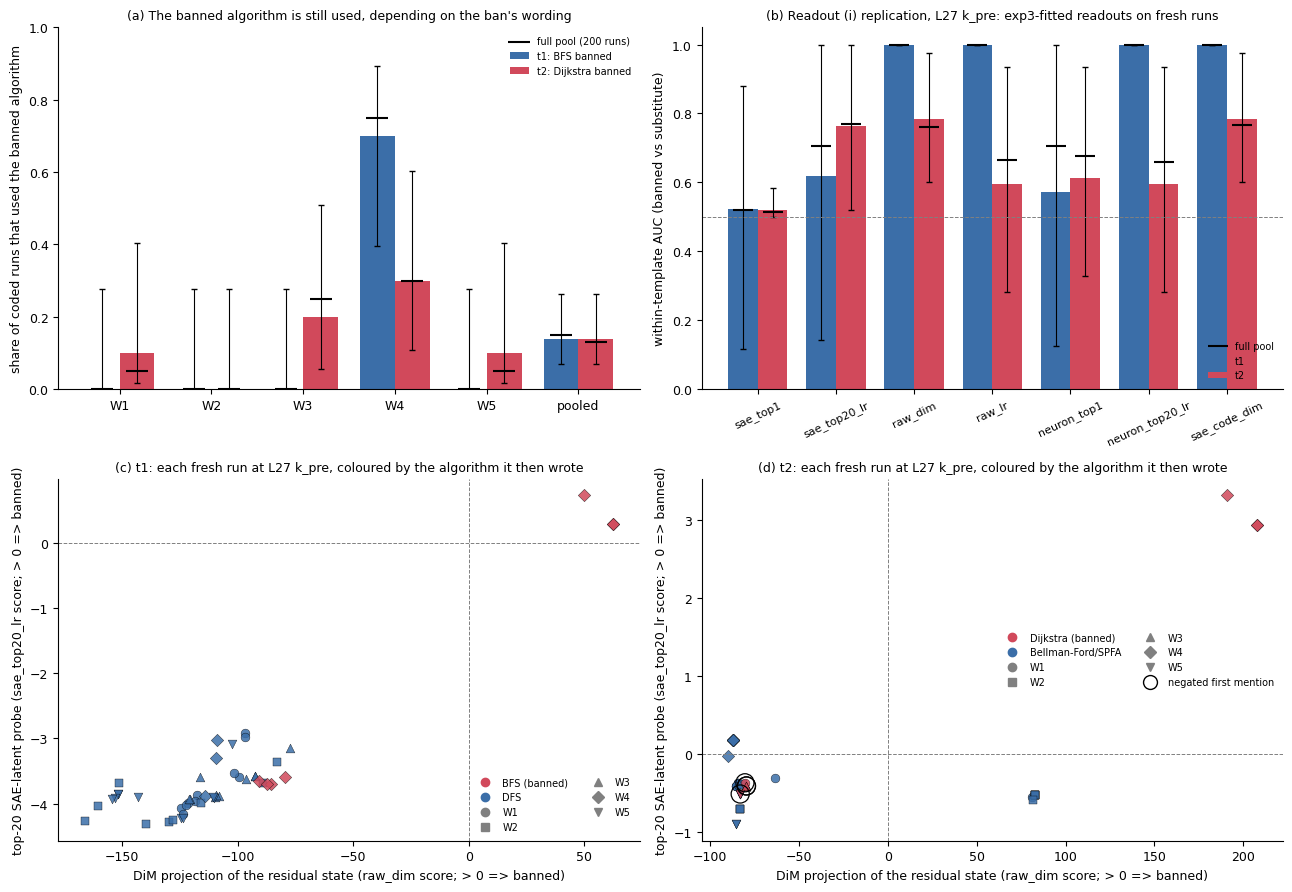

In [15]:
C = ["#3b6ea8", "#d1495b", "#66a182", "#edae49", "#7d5ba6", "#8d6a4f", "#4f4f4f"]  # src/figures.py palette
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) banned share per template with Wilson CIs; black ticks = the full 200-run pool
ax = axes[0, 0]
groups = TEMPLATE_IDS + ["pooled"]
x = np.arange(len(groups))
for j, t in enumerate(TASKS):
    per = FRESH_SUMMARY["per_task"][t]
    v = np.array([np.nan if per[w]["banned_share"] is None else per[w]["banned_share"] for w in groups])
    lo = np.array([np.nan if per[w]["banned_share_wilson"][0] is None else per[w]["banned_share_wilson"][0] for w in groups])
    hi = np.array([np.nan if per[w]["banned_share_wilson"][1] is None else per[w]["banned_share_wilson"][1] for w in groups])
    xs = x + (j - 0.5) * 0.38
    ax.bar(xs, v, 0.38, color=C[j], label=f"{t}: {LABEL_NAME[BANNED[t]]} banned")
    ax.errorbar(xs, v, yerr=[v - lo, hi - v], fmt="none", ecolor="k", capsize=2, lw=0.8)
    ax.scatter(xs, [REF["fresh_pool_summary"][t][w]["banned_share"] for w in groups], marker="_", s=260, color="k",
               zorder=3, label="full pool (200 runs)" if j == 0 else None)
ax.set_xticks(x, groups)
ax.set_ylim(0, 1)
ax.set_ylabel("share of coded runs that used the banned algorithm")
ax.set_title("(a) The banned algorithm is still used, depending on the ban's wording", fontsize=9)
ax.legend(frameon=False, fontsize=7)

# (b) within-template AUC of every readout with bootstrap CIs; black ticks = full pool; dashed = chance
ax = axes[0, 1]
x = np.arange(len(METHODS))
for j, t in enumerate(TASKS):
    key = f"{t}|L{READOUT_LAYER}|k_pre"
    tr = REPLICATION["configs"].get(key, {}).get("transfer_from_exp3", {})
    v = np.array([tr.get(m, {}).get("auc_within_template", np.nan) for m in METHODS], dtype=float)
    ci = [tr.get(m, {}).get("within_ci_runs") or [None, None] for m in METHODS]
    lo = np.array([np.nan if c[0] is None else c[0] for c in ci])
    hi = np.array([np.nan if c[1] is None else c[1] for c in ci])
    xs = x + (j - 0.5) * 0.38
    ax.bar(xs, v, 0.38, color=C[j], label=t)
    ax.errorbar(xs, v, yerr=[np.clip(v - lo, 0, None), np.clip(hi - v, 0, None)], fmt="none", ecolor="k", capsize=2,
                lw=0.8)
    ax.scatter(xs, [REF["readout_i_replication_k_pre"][key]["transfer_from_exp3"][m]["auc_within_template"]
                    for m in METHODS], marker="_", s=200, color="k", zorder=3,
               label="full pool" if j == 0 else None)
ax.axhline(0.5, color="grey", lw=0.7, ls="--")
ax.set_xticks(x, METHODS, rotation=25, fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("within-template AUC (banned vs substitute)")
ax.set_title(f"(b) Readout (i) replication, L{READOUT_LAYER} k_pre: exp3-fitted readouts on fresh runs", fontsize=9)
ax.legend(frameon=False, fontsize=7, loc="lower right")

# (c, d) every run as a point in the plane of two readout directions at L27 k_pre, coloured by what it then wrote
MARK = dict(zip(TEMPLATE_IDS, ["o", "s", "^", "D", "v"]))
for ax, t, letter in zip(axes[1], TASKS, ("c", "d")):
    for lab_, col in ((SUBSTITUTE[t], C[0]), (BANNED[t], C[1])):
        for w in TEMPLATE_IDS:
            rr = [r for r in C1_ROWS if r["task"] == t and r["label"] == lab_ and r["template"] == w and r["scores"]]
            if rr:
                ax.scatter([r["scores"]["raw_dim"] for r in rr], [r["scores"]["sae_top20_lr"] for r in rr], color=col,
                           marker=MARK[w], s=40, alpha=0.85, edgecolors="k", linewidths=0.3)
    # ring the runs whose first mention of the banned name is a negation ("I won't use Dijkstra")
    neg = [r for r in C1_ROWS if r["task"] == t and r["negated_first_mention"] and r["scores"]]
    ax.scatter([r["scores"]["raw_dim"] for r in neg], [r["scores"]["sae_top20_lr"] for r in neg], s=170,
               facecolors="none", edgecolors="k", linewidths=0.9)
    ax.axvline(0, color="grey", ls="--", lw=0.7)
    ax.axhline(0, color="grey", ls="--", lw=0.7)
    ax.set_xlabel("DiM projection of the residual state (raw_dim score; > 0 => banned)")
    ax.set_ylabel("top-20 SAE-latent probe (sae_top20_lr score; > 0 => banned)")
    ax.set_title(f"({letter}) {t}: each fresh run at L{READOUT_LAYER} k_pre, coloured by the algorithm it then wrote",
                 fontsize=9)
    handles = [plt.Line2D([], [], marker="o", ls="", color=C[1], label=f"{LABEL_NAME[BANNED[t]]} (banned)"),
               plt.Line2D([], [], marker="o", ls="", color=C[0], label=LABEL_NAME[SUBSTITUTE[t]])] + \
              [plt.Line2D([], [], marker=MARK[w], ls="", color="grey", label=w) for w in TEMPLATE_IDS] + \
              ([plt.Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor="k", markersize=10,
                           label="negated first mention")] if neg else [])
    ax.legend(handles=handles, frameon=False, fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

## Takeaways

With the default settings (all 100 demo runs, 2000 bootstrap draws, 200 placebo draws), on this subset:

- **A ban shifts the choice without removing it, and the wording matters.** T1's BFS ban is broken almost only under W4 ("Breadth-first search (BFS) is not allowed here."): 7/10 BFS here and 15/20 in the full pool, against 0 for the other four templates. T2's Dijkstra share is 0.14 (full pool 0.13), mostly under W3/W4. Runs that comply land on the substitute: DFS for T1, Bellman-Ford/SPFA for T2 (one T2 run is `other`).
- **The simplest direction transfers best.** The DiM direction fitted on exp3 orders the fresh runs perfectly within a template on T1 (AUC 1.00) and well on T2 (0.78; full pool 0.76). The single top SAE latent stays at chance (0.52 / 0.52) because it is silent on most runs of both classes. No SAE-based readout does better than DiM; DiM on the SAE code only ties it.
- **The ordering transfers, the threshold does not.** At "score > 0", no readout catches more than 3 of the 7 banned runs, and the single top latent catches none on T2. This holds even where the within-template AUC is 1.00. The exp3 midpoint does not carry over to the fresh prompts.
- **T2's misses are the negated mentions.** The Dijkstra runs that sit inside the Bellman-Ford/SPFA cluster in panel (d) are the ringed ones, where the first mention of Dijkstra is a negation. Without them, only the two W4 Dijkstra runs remain, and every readout except the single top latent reaches a pooled AUC of 1.00 (column `pooled AUC without negated`), as in the full pool.
- **Controls.** The shuffled-label placebos give about 0.50, and the re-derivation has no mismatches. The SAE base->instruct transfer test fails at every layer, so the latent readouts are descriptive only and flagged as out-of-distribution.

**Scaling up.** The config cell already uses the original `N_BOOT` (2000) and `N_PLACEBO` (200). To replay the stages on all 200 fresh-pool runs:
1. Regenerate the data file from the artifact's `full_method_out.json` with `python make_mini_demo_data.py --src <artifact>/full_method_out.json --per-cell 20`.
2. Point `load_data()` at that local file instead of the GitHub URL.

The replay then reproduces the pipeline's numbers (see the fidelity check in section 6). The GPU stages (`vllm1`, `vllm2`, `hf`) need the artifact's own environment: `uv run method.py --stage <name>`, about 1 GPU-hour on a 16 GB card.